# Lab 11: Spatial community composition

## BIO597 Spatial Analysis of Biodiversity

How does our view of an amphibian community change when a **site** is a 10 km,
20 km, or 40 km grid cell? Does community similarity decline with distance?
Can climate and geographic separation help explain the differences?

We will use the original Maine amphibian occurrences and WorldClim rasters to:

1. Build site-by-species matrices at three grid grains.
2. Map richness and compare distance decay of Jaccard similarity.
3. Fit a generalized dissimilarity model (GDM) at each grain.
4. Interpret how spatial aggregation and sampling affect the results.

Run from `docs/labs`. Use the same data and settings across grains so that
changes in the definition of a site are the main comparison.

## 0. Environment and imports

Install the `gdmbayes` package first

In [2]:
pip install gdmbayes


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 68.3 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 53.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 73.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 76.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 72.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 59.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 64.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 619.6/619.6 kB 36.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 68.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 73.

In [3]:
pip install rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 113.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [rasterio]1/2 [rasterio]
Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.mask import mask
from shapely.geometry import box
from scipy.spatial.distance import pdist, squareform, jaccard
from gdmbayes import GDM

CRS = "EPSG:26919"  # UTM zone 19N: distances in meters, suitable for Maine.
GRAINS = [10, 20, 40]  # Cell width in kilometers.
MIN_RECORDS = 2
OUTPUT = Path("outputs/Lab11")
OUTPUT.mkdir(parents=True, exist_ok=True)

## Exercise 1: Define sites and compare communities

### 1. Load occurrences and the Maine boundary

Retain named species and points within Maine. Each occurrence is a record,
not necessarily a different individual. Species names are used as supplied;
synonyms or identification errors can affect the community matrix.

Maine records: 14466
Species labels: 21


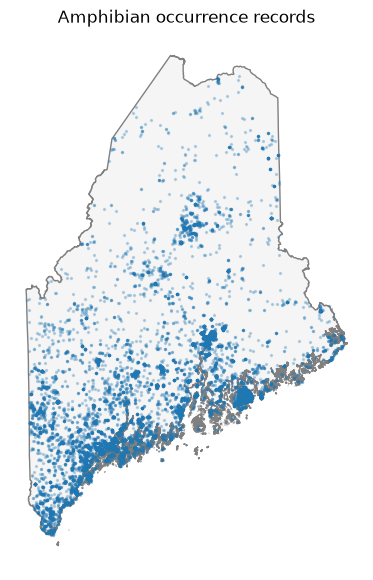

In [5]:
maine = gpd.read_file("ME_ShapeFiles/Maine_State_Boundary.shp").to_crs(CRS).dissolve()
records = gpd.read_file("../data/amphibians.geojson").to_crs(CRS)
records = records.dropna(subset=["species"])
records = records[records.species != ""]
records = gpd.clip(records, maine)

print("Maine records:", len(records))
print("Species labels:", records.species.nunique())

ax = maine.plot(color="whitesmoke", edgecolor="gray", figsize=(6, 7))
records.plot(ax=ax, markersize=2, alpha=0.25)
ax.set_title("Amphibian occurrence records")
ax.set_axis_off()
plt.show()

### 2. Aggregate records to a spatial grid

**Grain** is the width of a grid cell. A larger cell pools records from more
places. Our grids share a fixed origin, so 10 km cells nest within 20 km cells,
and 20 km cells nest within 40 km cells.

The helper below assigns each point a column and row, counts records by site
and species, and draws the occupied cells. `//` means integer division: it
finds which cell contains a coordinate. We clip cell outlines to Maine for
mapping, but use the original square centers for geographic distances.

Only cells meeting `MIN_RECORDS` become sites. Gray areas on the maps have no
retained site; they are **not evidence of zero richness**. Coastal cells contain
less land than interior cells, even at the same nominal grain.

In [6]:
# A fixed southwest grid corner, in UTM meters.
x0 = 320_000
y0 = 4_720_000


def grid_communities(grain_km):
    width = grain_km * 1000
    points = records.copy()
    points["col"] = ((points.geometry.x - x0) // width).astype(int)
    points["row"] = ((points.geometry.y - y0) // width).astype(int)
    points["site_id"] = points.col.astype(str) + "_" + points.row.astype(str)

    community = pd.crosstab(points.site_id, points.species)
    cell_locations = points[["site_id", "col", "row"]].drop_duplicates()
    cells = []
    for cell in cell_locations.itertuples():
        x = x0 + cell.col * width
        y = y0 + cell.row * width
        cells.append({"site_id": cell.site_id, "xc": x + width / 2,
                      "yc": y + width / 2, "geometry": box(x, y, x + width, y + width)})

    sites = gpd.GeoDataFrame(cells, crs=CRS).set_index("site_id")
    sites = gpd.clip(sites, maine).sort_index()
    community = community.reindex(sites.index)
    sites["n_records"] = community.sum(axis=1)
    sites["richness"] = (community > 0).sum(axis=1)
    sites = sites[sites.n_records >= MIN_RECORDS].copy()
    community = community.loc[sites.index]
    return sites, community

In [7]:
sites_by_grain = {}
communities = {}
grain_summary = pd.DataFrame()

for grain in GRAINS:
    sites, community = grid_communities(grain)
    sites_by_grain[grain] = sites
    communities[grain] = community
    grain_summary.loc[grain, "n_sites"] = len(sites)
    grain_summary.loc[grain, "n_records"] = sites.n_records.sum()
    grain_summary.loc[grain, "mean_richness"] = sites.richness.mean()
    grain_summary.loc[grain, "median_records_per_site"] = sites.n_records.median()

grain_summary.index.name = "grain_km"
display(grain_summary)
display(communities[20].head())

,n_sites,n_records,mean_richness,median_records_per_site
grain_km,,,,
10,536.0,14361.0,5.542910,9.0
20,206.0,14449.0,7.524272,19.5
40,67.0,14464.0,10.731343,63.0


species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana catesbeiana,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,...,Hemidactylium scutatum,Lithobates catesbeianus,Lithobates palustris,Lithobates pipiens,Necturus maculosus,Notophthalmus viridescens,Osteopilus septentrionalis,Plethodon cinereus,Pseudacris crucifer,Rana arvalis
site_id,,,,,,,,,,,,,,,,,,,,,
0_13,0,0,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
0_14,0,0,1,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10_10,0,19,0,0,12,0,16,0,8,0,...,1,11,21,0,0,7,0,28,19,2
10_11,2,7,6,0,29,0,7,0,11,5,...,0,6,18,2,0,6,0,5,15,0
10_12,62,118,14,0,87,4,99,2,22,22,...,67,78,35,78,0,51,0,136,104,7


`sites_by_grain` and `communities` store the results for each grain. For example,
`communities[20]` is the 20 km site-by-species count matrix.

### 3. Compare richness maps

Use one color scale across all three maps. Changing grain changes the area
represented by a site; higher richness in larger cells need not mean that the
underlying landscape has changed.

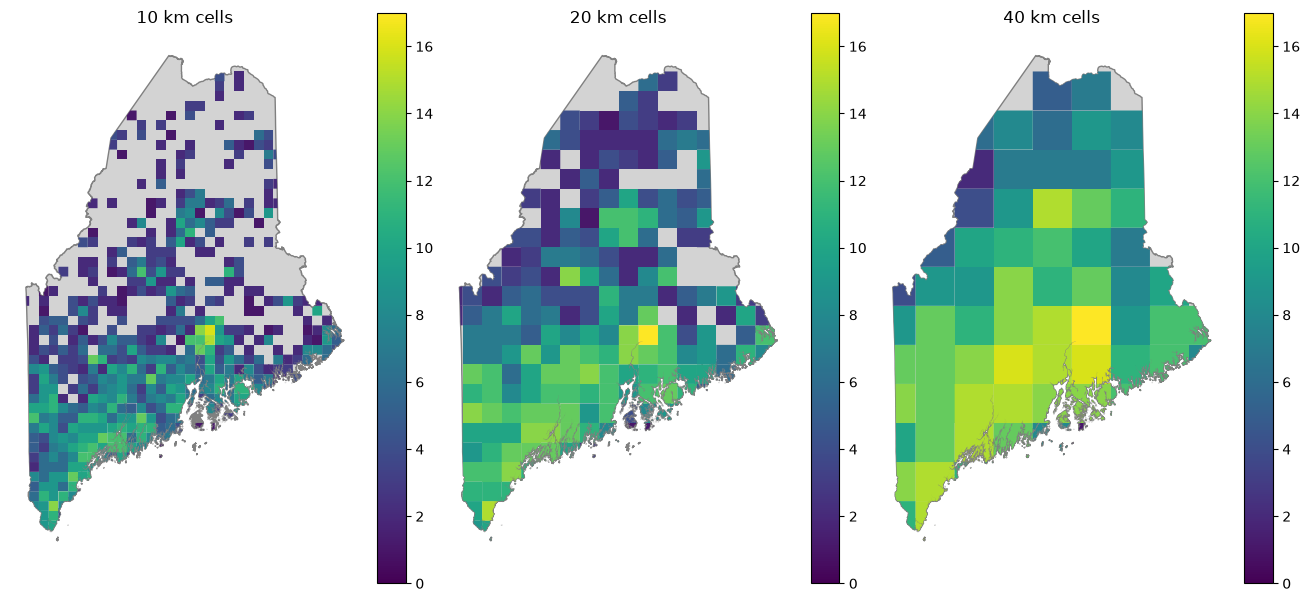

In [8]:
max_richness = max(sites.richness.max() for sites in sites_by_grain.values())
fig, axes = plt.subplots(1, 3, figsize=(13, 6), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    maine.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[grain].plot(ax=ax, column="richness", cmap="viridis",
                              vmin=0, vmax=max_richness, legend=True)
    ax.set_title(f"{grain} km cells")
    ax.set_axis_off()
fig.savefig(OUTPUT / "richness_by_grain.png", dpi=150)
plt.show()

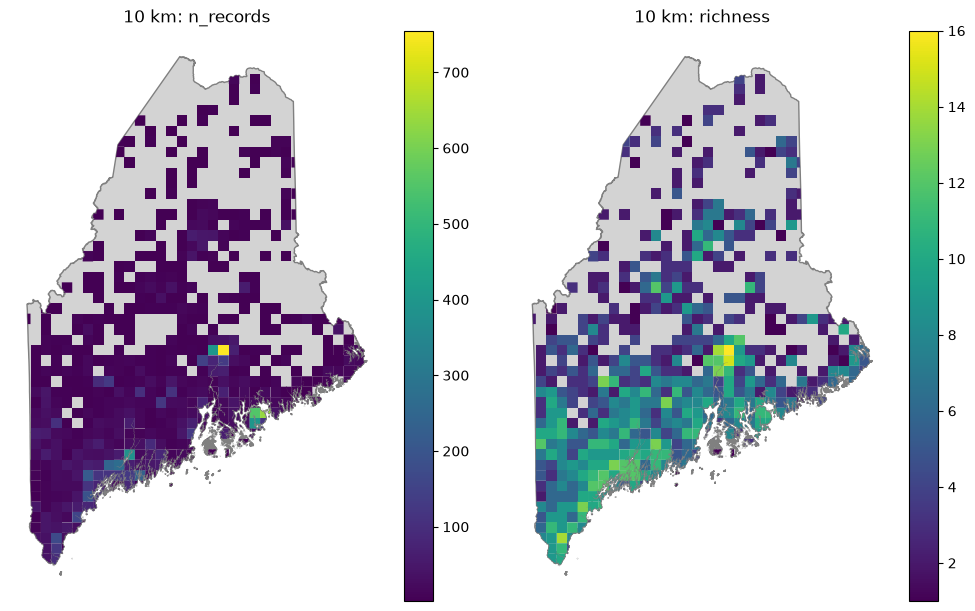

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6), layout="constrained")
for ax, column in zip(axes, ["n_records", "richness"]):
    maine.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[10].plot(ax=ax, column=column, legend=True)
    ax.set_title(f"10 km: {column}")
    ax.set_axis_off()
plt.show()

**Discuss:** Which apparent hotspots persist across grains? Where do record
numbers and richness coincide? How would incomplete sampling or small coastal
land areas affect the comparison? Later, try `MIN_RECORDS = 5` and rerun the
analysis. This excludes sparsely recorded sites; it does not equalize effort.

### 4. Species lists, turnover, and nestedness

Use **Jaccard dissimilarity** on presence/absence, as in Lab10. Jaccard
similarity is `1 - dissimilarity`: one means identical lists; zero means no
shared species. These compare recorded lists, not known true communities.

A poorer list may be a subset of a richer list (**nestedness**), or some species
may be replaced by others (**turnover**). Total Jaccard dissimilarity can reflect
both. The two invented examples below have the same dissimilarity.

In [10]:
print("Subset, AB versus ABCD:", jaccard([True, True, False, False],
                                        [True, True, True, True]))
print("Replacement, ABC versus ACD:", jaccard([True, True, True, False],
                                             [True, False, True, True]))

Subset, AB versus ABCD: 0.5
Replacement, ABC versus ACD: 0.5


### 5. Calculate all site pairs

SciPy's `pdist` calculates each unique pair once, in a fixed order. Using the
same site order for the community matrix and coordinates gives matching
vectors of dissimilarity and distance. No species-list comparison is made
for unsampled cells.

In [11]:
def community_pairs(sites, community):
    presence = community.loc[sites.index] > 0
    dissimilarity = pdist(presence, metric="jaccard")
    distance_km = pdist(sites[["xc", "yc"]]) / 1000
    return pd.DataFrame({"distance_km": distance_km,
                         "jaccard": dissimilarity,
                         "similarity": 1 - dissimilarity})


pairs_by_grain = {}
for grain in GRAINS:
    pairs_by_grain[grain] = community_pairs(sites_by_grain[grain], communities[grain])

display(pairs_by_grain[20].head())

,distance_km,jaccard,similarity
0,20.000000,0.666667,0.333333
1,208.806130,1.000000,0.000000
2,203.960781,0.846154,0.153846
3,200.997512,0.882353,0.117647
4,200.000000,1.000000,0.000000


### 6. Distance decay of similarity

Do more distant sites tend to share fewer species? Plot all pairs, then average
similarity within 50 km distance bands to make the broad pattern easier to see.
The averages use all pairs in each band.

A distance-decay pattern may reflect environmental differences, dispersal,
history, or sampling. Pairs reuse the same sites, so they are **not independent
replicates**. We describe the pattern rather than report an ordinary regression
p-value treating every pair as independent.

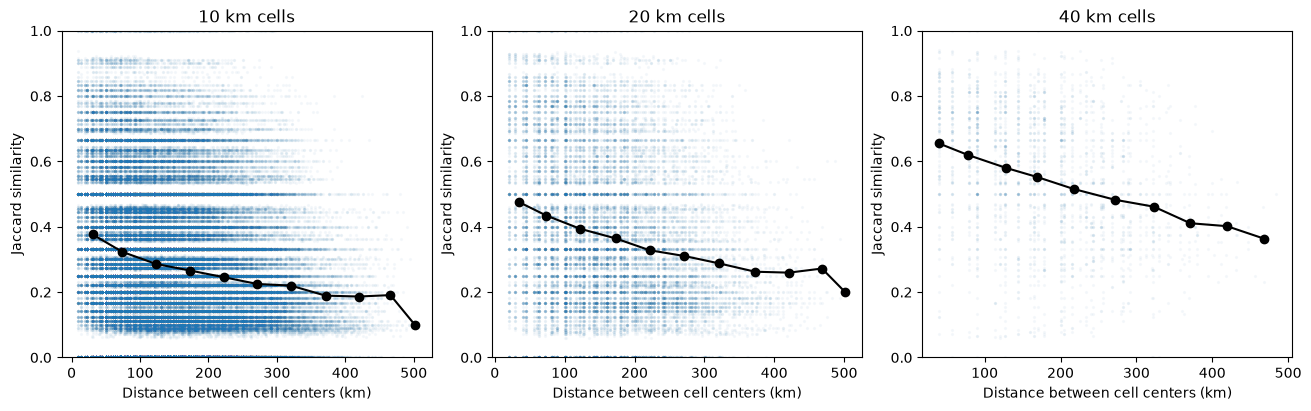

,n_sites,n_records,mean_richness,median_records_per_site,distance_similarity_rho
grain_km,,,,,
10,536.0,14361.0,5.542910,9.0,-0.199370
20,206.0,14449.0,7.524272,19.5,-0.219776
40,67.0,14464.0,10.731343,63.0,-0.314197


In [12]:
def distance_bands(pairs):
    rows = []
    for lower in range(0, 650, 50):
        in_band = pairs[(pairs.distance_km >= lower) & (pairs.distance_km < lower + 50)]
        if len(in_band) == 0:
            continue
        rows.append({"distance_km": in_band.distance_km.mean(),
                     "mean_similarity": in_band.similarity.mean(),
                     "n_pairs": len(in_band)})
    return pd.DataFrame(rows)


binned_decay = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    pairs = pairs_by_grain[grain]
    bands = distance_bands(pairs)
    binned_decay[grain] = bands
    ax.scatter(pairs.distance_km, pairs.similarity, s=2, alpha=0.03)
    ax.plot(bands.distance_km, bands.mean_similarity, color="black", marker="o")
    ax.set(title=f"{grain} km cells", xlabel="Distance between cell centers (km)",
           ylabel="Jaccard similarity", ylim=(0, 1))
    grain_summary.loc[grain, "distance_similarity_rho"] = pairs.distance_km.corr(
        pairs.similarity, method="spearman")
fig.savefig(OUTPUT / "distance_decay_by_grain.png", dpi=150)
plt.show()

display(grain_summary)

**Discuss:** Does the shape or strength of distance decay change with grain?
The Spearman correlation (`rho`) is a descriptive summary, not an independent-
pair significance test. Check the number of pairs in `binned_decay[10]` before
interpreting the ends of the curve. Why might aggregation increase similarity?

### 7. Map differences among neighboring sites

For each sampled cell, average its Jaccard dissimilarity to sampled neighbors
within 1.5 cell widths. This includes touching side and diagonal neighbors.
Cells with no sampled neighbor receive a missing value.

This is a map of **local compositional difference**, not richness or a rate per
kilometer. The comparison distance grows with grain, so the maps have different
spatial support. Missing cells are not places with zero turnover.

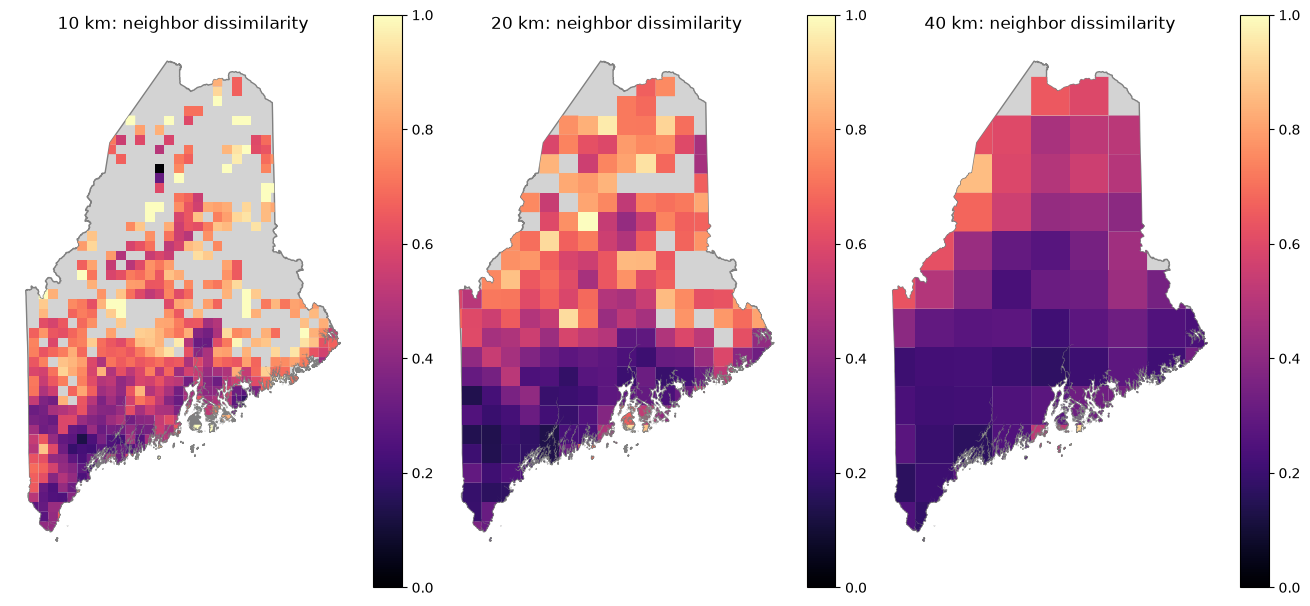

In [13]:
for grain in GRAINS:
    sites = sites_by_grain[grain]
    pairs = pairs_by_grain[grain]
    distances = squareform(pairs.distance_km.to_numpy())
    dissimilarities = squareform(pairs.jaccard.to_numpy())
    local_difference = []
    for i in range(len(sites)):
        neighbors = (distances[i] > 0) & (distances[i] <= 1.5 * grain)
        if neighbors.any():
            local_difference.append(dissimilarities[i, neighbors].mean())
        else:
            local_difference.append(np.nan)
    sites["neighbor_dissimilarity"] = local_difference

fig, axes = plt.subplots(1, 3, figsize=(13, 6), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    maine.plot(ax=ax, color="lightgray", edgecolor="gray")
    sites_by_grain[grain].plot(ax=ax, column="neighbor_dissimilarity", cmap="magma",
                              vmin=0, vmax=1, legend=True)
    ax.set_title(f"{grain} km: neighbor dissimilarity")
    ax.set_axis_off()
fig.savefig(OUTPUT / "neighbor_dissimilarity_by_grain.png", dpi=150)
plt.show()

**Discuss:** Are the most compositionally different neighborhoods also the
richest? Inspect two contrasting sites' species lists. Could a high neighbor
dissimilarity reflect an undersampled site or a subset pattern rather than
species replacement?

## Exercise 2: Generalized dissimilarity modeling at each grain

### 8. Describe the climate of each site

Distance decay combines several possible explanations. GDM relates pairwise
community dissimilarity to **climate differences and geographic separation**.
We will use two familiar [WorldClim variables](https://www.worldclim.org/data/bioclim.html):

| Predictor | Variable | Units |
| --- | --- | --- |
| `temperature_c` | BIO1, annual mean temperature | °C |
| `precipitation_mm` | BIO12, annual precipitation | mm/year |

Calculate the mean of valid raster pixels intersecting each cell's Maine land
area. This represents the site rather than weighting climate by occurrence
locations. Edge pixels are included and equally weighted; this is an approximate
zonal mean, not an exact area-weighted average. The climate layers summarize
1970–2000 conditions, while occurrences span multiple years.

In [14]:
CLIMATE_DIR = Path("../data/bioclim_ME")
CLIMATE_LAYERS = {"temperature_c": 1, "precipitation_mm": 12}

CLIMATE_LAYERS = {
    'wc2.1_2.5m_bio_1.tif':  'temperature_c',
    'wc2.1_2.5m_bio_2.tif':  'diurnal_range_c',
    'wc2.1_2.5m_bio_3.tif':  'isothermality',
    'wc2.1_2.5m_bio_4.tif':  'temp_seasonality',
    'wc2.1_2.5m_bio_5.tif':  'max_temp_warmest',
    'wc2.1_2.5m_bio_6.tif':  'min_temperature_coldest',
    'wc2.1_2.5m_bio_7.tif':  'temp_range',
    'wc2.1_2.5m_bio_8.tif':  'temp_wettest_q',
    'wc2.1_2.5m_bio_9.tif':  'temp_driest_q',
    'wc2.1_2.5m_bio_10.tif': 'temp_warmest_q',
    'wc2.1_2.5m_bio_11.tif': 'temp_coldest_q',
    'wc2.1_2.5m_bio_12.tif': 'precip',
    'wc2.1_2.5m_bio_13.tif': 'precip_wettest_m',
    'wc2.1_2.5m_bio_14.tif': 'precip_driest_m',
    'wc2.1_2.5m_bio_15.tif': 'precip_seasonality',
    'wc2.1_2.5m_bio_16.tif': 'precip_wettest_q',
    'wc2.1_2.5m_bio_17.tif': 'precip_driest_q',
    'wc2.1_2.5m_bio_18.tif': 'precip_warmest_q',
    'wc2.1_2.5m_bio_19.tif': 'precip_coldest_q',
}

In [15]:
CLIMATE_DIR = Path("../data/bioclim_ME")
predictors = list(CLIMATE_LAYERS.values())

def add_climate(sites):
    sites = sites.copy()
    for f, name in CLIMATE_LAYERS.items():
        path = CLIMATE_DIR / f
        means = []
        with rasterio.open(path) as raster:
            raster_sites = sites.to_crs(raster.crs)
            for geometry in raster_sites.geometry:
                pixels, transform = mask(raster, [geometry], crop=True,
                                         filled=False, all_touched=True)
                valid_pixels = pixels[0].compressed()
                if len(valid_pixels) == 0:
                    means.append(np.nan)
                else:
                    means.append(valid_pixels.mean())
        sites[name] = means
    return sites


climate_sites = {}
for grain in GRAINS:
    sites = add_climate(sites_by_grain[grain])
    climate_sites[grain] = sites
    print(grain, "km: sites missing climate =", sites[predictors].isna().any(axis=1).sum())

display(climate_sites[20][predictors].describe())
display(climate_sites[20][predictors].corr())

10 km: sites missing climate = 2
20 km: sites missing climate = 0
40 km: sites missing climate = 0


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
count,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000,206.000000
mean,5.218520,11.498158,28.274063,1033.787354,25.046804,-15.621861,40.668667,8.298516,0.555861,17.609245,-7.999976,1110.662109,115.104843,68.948303,14.739941,323.692291,227.837341,286.500214,255.011475
std,1.641561,0.860914,1.175044,74.553055,1.110067,3.115006,2.733482,7.370056,11.616377,1.014724,2.614713,82.117210,11.735734,9.893036,2.947046,28.241024,26.123575,28.132027,40.509674
min,2.556659,7.847515,25.570068,804.233154,22.449066,-20.644110,30.656137,-3.888381,-10.563295,15.507066,-12.238143,934.500000,98.190475,48.349998,9.569618,285.266663,171.800003,244.130432,189.899994
25%,3.564440,11.211460,27.622958,984.309082,24.122819,-18.196313,39.398399,2.038529,-8.609399,16.686266,-10.436095,1043.357117,106.321428,60.151429,12.293186,301.907135,205.087967,260.885712,224.171425
50%,5.517196,11.767240,28.390799,1044.147583,25.045540,-15.961810,41.377542,4.310979,-5.882222,17.711107,-7.882091,1102.228577,111.828571,69.585712,14.078347,317.335724,228.500000,286.385712,247.170654
75%,6.611632,12.013831,28.954429,1092.335693,25.981948,-13.284026,42.508915,16.104358,17.058212,18.446830,-5.891643,1156.397430,121.720394,78.111713,17.352146,337.852684,252.375751,304.528572,285.008568
max,8.595151,12.854962,31.398592,1157.964478,27.478651,-7.432017,44.926758,18.014133,19.936588,19.936588,-1.919664,1346.000000,149.666672,86.523811,21.158058,413.583344,275.071442,377.200012,366.666656


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
temperature_c,1.000000,-0.450125,0.453418,-0.900249,0.714740,0.960518,-0.804325,-0.845391,0.809214,0.916906,0.984309,0.636708,0.556191,0.827003,-0.580414,0.395672,0.814784,-0.876716,0.767830
diurnal_range_c,-0.450125,1.000000,0.504578,0.700337,0.240989,-0.652147,0.841035,0.312878,-0.616447,-0.141659,-0.560207,-0.591539,-0.647178,-0.390886,-0.188796,-0.677500,-0.392556,0.413871,-0.596993
isothermality,0.453418,0.504578,1.000000,-0.253292,0.712811,0.290105,-0.041123,-0.457658,0.194207,0.563511,0.387783,0.185064,0.047779,0.478399,-0.641531,-0.102356,0.450429,-0.319650,0.234609
temp_seasonality,-0.900249,0.700337,-0.253292,1.000000,-0.353389,-0.977512,0.970436,0.763096,-0.855253,-0.653155,-0.962212,-0.814564,-0.766223,-0.832960,0.338317,-0.662533,-0.820881,0.767505,-0.877150
max_temp_warmest,0.714740,0.240989,0.712811,-0.353389,1.000000,0.500827,-0.164629,-0.629835,0.373760,0.921634,0.587311,0.118707,0.011519,0.499366,-0.747401,-0.178830,0.495911,-0.643436,0.287060
min_temperature_coldest,0.960518,-0.652147,0.290105,-0.977512,0.500827,1.000000,-0.936188,-0.791294,0.856364,0.780180,0.991669,0.742229,0.681309,0.835301,-0.435471,0.559509,0.822358,-0.822537,0.833686
temp_range,-0.804325,0.841035,-0.041123,0.970436,-0.164629,-0.936188,1.000000,0.645962,-0.824106,-0.514797,-0.891573,-0.797618,-0.771725,-0.749094,0.192731,-0.710225,-0.735748,0.676043,-0.833472
temp_wettest_q,-0.845391,0.312878,-0.457658,0.763096,-0.629835,-0.791294,0.645962,1.000000,-0.713554,-0.764277,-0.826943,-0.685697,-0.611228,-0.812325,0.537182,-0.463142,-0.818032,0.781286,-0.803095
temp_driest_q,0.809214,-0.616447,0.194207,-0.855253,0.373760,0.856364,-0.824106,-0.713554,1.000000,0.619113,0.842836,0.745076,0.747686,0.783673,-0.212484,0.679231,0.754367,-0.798050,0.862312
temp_warmest_q,0.916906,-0.141659,0.563511,-0.653155,0.921634,0.780180,-0.514797,-0.764277,0.619113,1.000000,0.834296,0.364328,0.262982,0.683175,-0.711608,0.079142,0.673069,-0.809681,0.528140


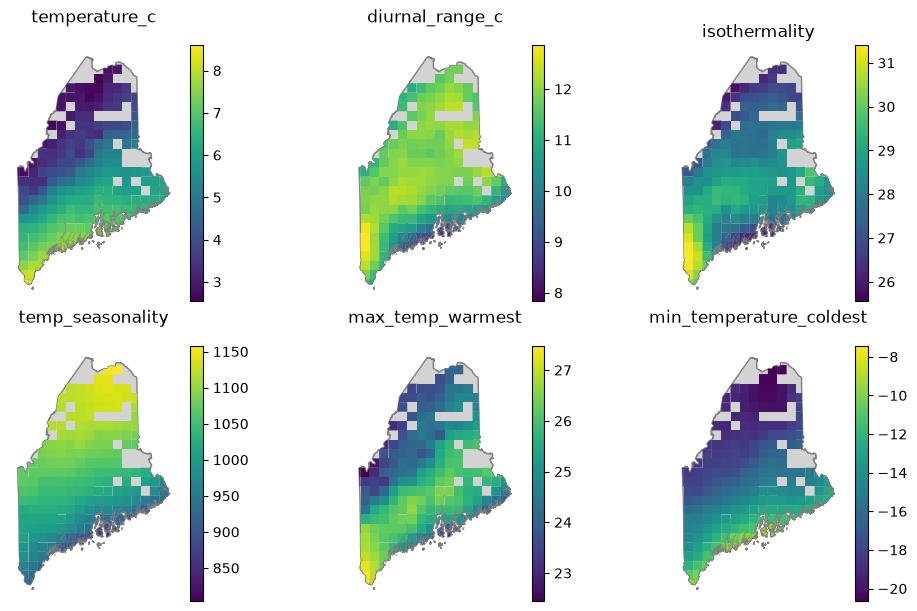

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6), layout="constrained")
for ax, name in zip(axes.flat, predictors):
    maine.plot(ax=ax, color="lightgray", edgecolor="gray")
    climate_sites[20].plot(ax=ax, column=name, legend=True)
    ax.set_title(name)
    ax.set_axis_off()
plt.show()

### 9. Prepare GDM inputs

GDM models dissimilarity between pairs, not the occurrence of one species.
Its fitted response is between 0 and 1. Smooth, increasing transformations
allow a given climate difference to matter more in some parts of a gradient
than in others. See [Ferrier et al. (2007)](https://doi.org/10.1111/j.1472-4642.2007.00341.x).

The installed [`gdmbayes` package](https://github.com/butterman0/gdmbayes) expects:

- `X`: one row per site, with **`xc`, `yc`, `time_idx` first**, then climate.
  Coordinates are projected meters. All `time_idx` values are zero because we
  pool years; this is a required placeholder, not a fitted temporal predictor.
- `y`: Jaccard dissimilarities in `pdist` order for those same rows.

Drop sites without climate, then align the matrix to the retained site IDs.
Recalculate pairs after that selection; keeping an earlier pair vector would
misalign the response and predictors.

In [17]:
model_sites = {}
model_X = {}
model_y = {}

for grain in GRAINS:
    sites = climate_sites[grain].dropna(subset=predictors).copy()
    community = communities[grain].loc[sites.index]
    X = sites[["xc", "yc"]].copy()
    X["time_idx"] = 0
    X[predictors] = sites[predictors]
    y = pdist(community > 0, metric="jaccard")
    model_sites[grain] = sites
    model_X[grain] = X
    model_y[grain] = y
    print(grain, "km:", len(X), "sites and", len(y), "pairs")

display(model_X[20].head())

10 km: 534 sites and 142311 pairs
20 km: 206 sites and 21115 pairs
40 km: 67 sites and 2211 pairs


,xc,yc,time_idx,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,...,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q
site_id,,,,,,,,,,,,,,,,,,,,,
0_13,330000.0,4990000.0,0,3.385630,11.463556,27.719982,1073.698120,23.278666,-18.071556,41.350224,...,16.109333,-10.379407,1121.111084,118.777779,66.444443,17.263128,343.111115,219.666672,343.111115,234.555557
0_14,330000.0,5010000.0,0,2.882517,10.941433,26.847387,1076.608765,22.553200,-18.197599,40.750801,...,15.664400,-10.876866,1265.500000,130.300003,79.099998,14.932753,377.200012,256.299988,377.200012,277.399994
10_10,530000.0,4930000.0,0,6.761517,10.824512,28.115656,972.173340,25.852631,-12.648065,38.500694,...,18.489717,-5.646893,1224.302979,130.666672,79.848488,14.034812,359.969696,260.242432,260.242432,312.272736
10_11,530000.0,4950000.0,0,6.514908,11.174660,28.175772,998.891724,26.135048,-13.522572,39.657619,...,18.557779,-6.263270,1159.285767,117.880951,79.523811,10.949160,329.166656,261.547607,264.833344,289.047607
10_12,530000.0,4970000.0,0,6.383919,11.642142,28.713531,1015.885071,26.488798,-14.056115,40.544918,...,18.668381,-6.611924,1074.457153,104.057144,71.228569,9.569618,295.371429,239.942856,266.571442,258.971436


### 10. Fit one standard GDM per grain

First fit a geography-only baseline, then geography plus temperature and precipitation. `knots=0` gives a simple
three-basis smooth response for each predictor. Keep the settings unchanged
across grains. Geography uses straight-line distance, not movement routes.

`explained_` is the fraction of **training deviance explained**, not R² or
held-out predictive accuracy. The importance values are fitted transformation
heights; they are not p-values or causal effects. Correlated climate and
geography can share explanatory information.

In [18]:
models = {}
predictions = {}
gdm_summary = pd.DataFrame()
importance = pd.DataFrame()

for grain in GRAINS:
    X = model_X[grain]
    y = model_y[grain]
    geography_only = GDM(geo=True, knots=0).fit(X[["xc", "yc", "time_idx"]], y)
    model = GDM(geo=True, knots=0).fit(X, y)
    models[grain] = model
    predictions[grain] = model.predict(X)
    gdm_summary.loc[grain, "n_sites"] = len(X)
    gdm_summary.loc[grain, "n_pairs"] = len(y)
    gdm_summary.loc[grain, "geography_only_deviance_pct"] = 100 * geography_only.explained_
    gdm_summary.loc[grain, "training_deviance_explained_pct"] = 100 * model.explained_
    for name, value in model.predictor_importance_.items():
        importance.loc[grain, name] = value

gdm_summary.index.name = "grain_km"
importance.index.name = "grain_km"
display(gdm_summary)
display(importance)

,n_sites,n_pairs,geography_only_deviance_pct,training_deviance_explained_pct
grain_km,,,,
10,534.0,142311.0,3.912066,12.076722
20,206.0,21115.0,4.766327,24.141084
40,67.0,2211.0,8.344085,48.132618


,temperature_c,diurnal_range_c,isothermality,temp_seasonality,max_temp_warmest,min_temperature_coldest,temp_range,temp_wettest_q,temp_driest_q,temp_warmest_q,temp_coldest_q,precip,precip_wettest_m,precip_driest_m,precip_seasonality,precip_wettest_q,precip_driest_q,precip_warmest_q,precip_coldest_q,geo
grain_km,,,,,,,,,,,,,,,,,,,,
10,0.220959,0.000000,0.000000,0.0,0.497165,0.000000,0.000000,0.290593,0.0,0.0,0.077010,0.000000,0.0,0.00000,0.051662,0.100263,0.670511,0.297703,0.0,0.061678
20,0.000000,0.000000,0.079730,0.0,0.588177,0.000000,0.000000,0.000000,0.0,0.0,0.423730,0.000000,0.0,0.14853,0.297225,0.000000,0.427361,0.370839,0.0,0.000000
40,0.000000,0.068439,0.403353,0.0,0.372460,0.037346,0.014904,0.000000,0.0,0.0,0.077133,0.127876,0.0,0.00000,0.193396,0.000000,0.000000,0.586438,0.0,0.240175


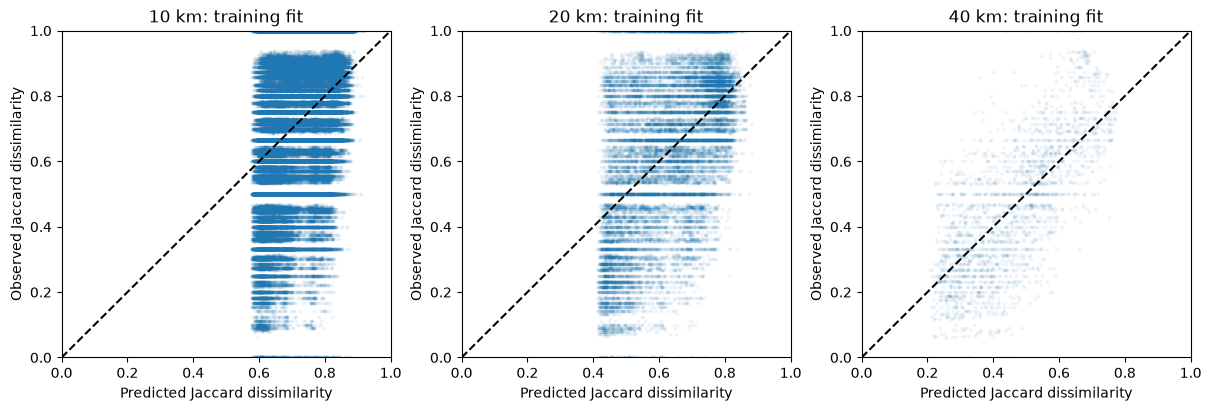

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, grain in zip(axes, GRAINS):
    ax.scatter(predictions[grain], model_y[grain], s=3, alpha=0.05)
    ax.plot([0, 1], [0, 1], color="black", linestyle="--")
    ax.set(title=f"{grain} km: training fit", xlabel="Predicted Jaccard dissimilarity",
           ylabel="Observed Jaccard dissimilarity", xlim=(0, 1), ylim=(0, 1))
fig.savefig(OUTPUT / "gdm_training_fit_by_grain.png", dpi=150)
plt.show()

**Discuss:** Where do predictions miss the observed dissimilarities? Why might
larger cells produce a different apparent fit? Different grains change the
sites, pairs, and response distribution, so deviance explained is not a
controlled contest between models on the same test data. A real prediction
test should hold out geographic groups of **sites**, not randomly split pairs
that still share sites with training data.

### 11. Read the climate transformations

Use `gdm_transform` to see how the fitted model stretches each climate gradient.
The helper varies one predictor while holding the other inputs fixed. It sums
the transformed contributions and subtracts the starting value, leaving that
predictor's cumulative effect.

A **steep segment** indicates more modeled community change across that climate
interval. A **flat segment** indicates little modeled change. The y axis is
partial ecological distance, not species richness, occurrence probability, or
a habitat optimum. Climate units stay on the x axis.

In [20]:
# Sort bioclim variable importance by values, so we can look at only the most relevant ones
sorted_cols = importance.sum().sort_values(ascending=False).index
importance_sorted = importance[sorted_cols].drop(columns=['geo'])
importance_sorted

,max_temp_warmest,precip_warmest_q,precip_driest_q,temp_coldest_q,precip_seasonality,isothermality,temp_wettest_q,temperature_c,precip_driest_m,precip,precip_wettest_q,diurnal_range_c,min_temperature_coldest,temp_range,temp_seasonality,temp_driest_q,temp_warmest_q,precip_wettest_m,precip_coldest_q
grain_km,,,,,,,,,,,,,,,,,,,
10,0.497165,0.297703,0.670511,0.077010,0.051662,0.000000,0.290593,0.220959,0.00000,0.000000,0.100263,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
20,0.588177,0.370839,0.427361,0.423730,0.297225,0.079730,0.000000,0.000000,0.14853,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
40,0.372460,0.586438,0.000000,0.077133,0.193396,0.403353,0.000000,0.000000,0.00000,0.127876,0.000000,0.068439,0.037346,0.014904,0.0,0.0,0.0,0.0,0.0


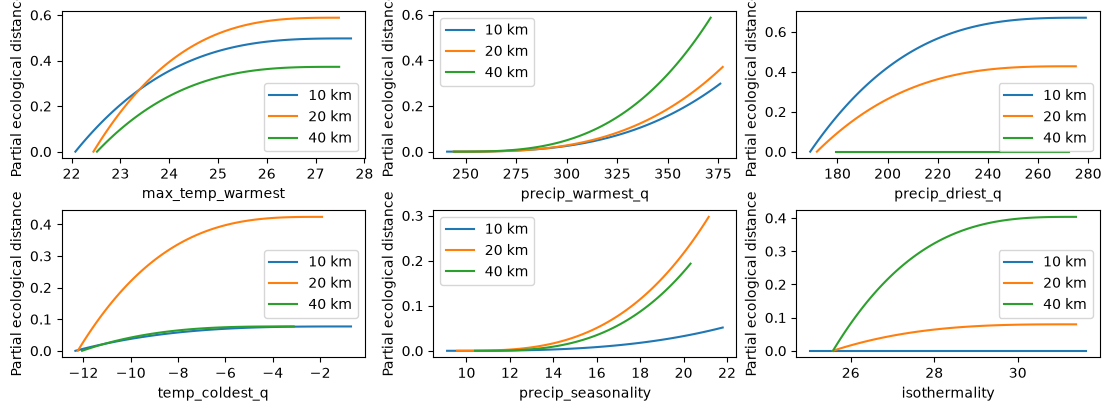

In [21]:
def climate_curve(model, X, predictor):
    curve = pd.DataFrame(index=range(100))
    for column in X.columns:
        curve[column] = X[column].median()
    curve[predictor] = np.linspace(X[predictor].min(), X[predictor].max(), 100)
    effect = model.gdm_transform(curve).sum(axis=1)
    effect = effect - effect[0]
    return pd.DataFrame({"value": curve[predictor], "effect": effect})


curves = {}

fig, axes = plt.subplots(2, 3, figsize=(11, 4), layout="constrained")
for ax, name in zip(axes.flat, importance_sorted.columns):
    for grain in GRAINS:
        curve = climate_curve(models[grain], model_X[grain], name)
        curves[(grain, name)] = curve
        ax.plot(curve.value, curve.effect, label=f"{grain} km")
    ax.set(xlabel=name, ylabel="Partial ecological distance")
    ax.legend()
fig.savefig(OUTPUT / "gdm_climate_curves_by_grain.png", dpi=150)
plt.show()

**Discuss:** Which climate intervals show the most modeled change? Do the curves
agree across grains? Compare their heights with `importance`. Curve ranges and
fitted coefficients change with grain; these are associations rather than
independent evidence of a physiological threshold or climate causation.

### 12. Compare the grains together

Keep site counts, observed patterns, and model fit in the same table. A coarser
grain pools species lists, smooths climate, reduces the number of sites, and
changes what a pairwise comparison represents.

In [22]:
comparison = grain_summary.join(gdm_summary, rsuffix="_gdm")
display(comparison)

,n_sites,n_records,mean_richness,median_records_per_site,distance_similarity_rho,n_sites_gdm,n_pairs,geography_only_deviance_pct,training_deviance_explained_pct
grain_km,,,,,,,,,
10,536.0,14361.0,5.542910,9.0,-0.199370,534.0,142311.0,3.912066,12.076722
20,206.0,14449.0,7.524272,19.5,-0.219776,206.0,21115.0,4.766327,24.141084
40,67.0,14464.0,10.731343,63.0,-0.314197,67.0,2211.0,8.344085,48.132618


## PCA map and biplot of expected community composition

As in Lab09, give the map and a PCA biplot the **same color key**. First transform
the environmental predictors with the fitted GDM. The package returns several
weighted spline components per predictor; sum these to get one transformed
column for each climate variable. Fit [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) without standardizing
these columns, so the GDM weights are preserved.

There are 19 climate predictors, and we will collapse these into 2 PCs for plotting. 
Red and green encode their rescaled scores; blue is held constant. More similar colors indicate more
similar **climate-associated expected composition**. Geographic distance is a
pairwise term and is excluded from this site-level transformation. The colors
are a visualization, not calibrated Jaccard distances or species-richness values.

The arrows show increasing transformed climate layers with the largest loadings. Their
lengths describe contributions to the displayed PCA pattern. Gray areas have no
modeled site. Set `pca_grain` to 10 or 40 to repeat the figure; each grain gets
its own PCA and color scale, so matching colors across runs are not a shared key.

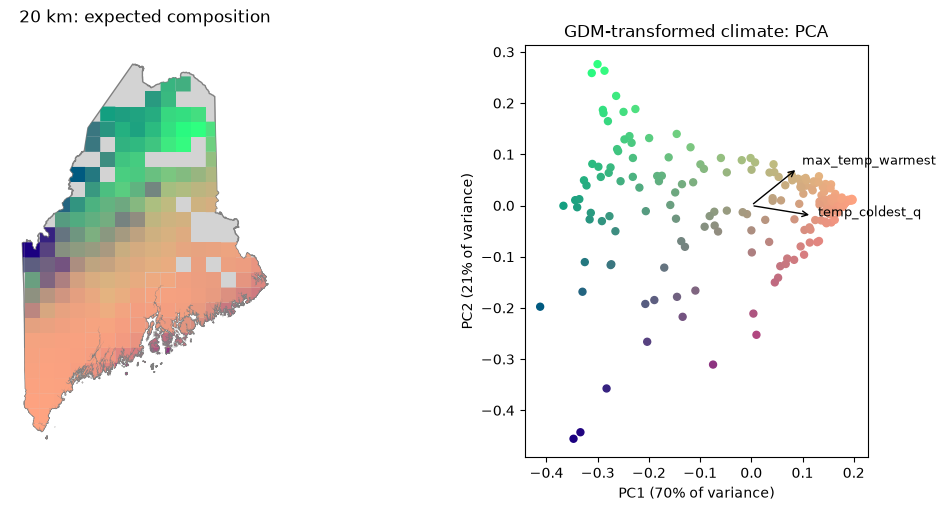

In [26]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

pca_grain = 20  # Try 10 or 40 as well.
X_biplot = model_X[pca_grain]
model = models[pca_grain]

# Sum each predictor's weighted spline components.
weighted_splines = model.gdm_transform(X_biplot)
n_basis = model.preprocessor_.n_spline_bases_
transformed = pd.DataFrame(index=X_biplot.index)
for i, name in enumerate(predictors):
    start = i * n_basis
    stop = start + n_basis
    transformed[name] = weighted_splines[:, start:stop].sum(axis=1)

pca = PCA(n_components=2)
scores = pca.fit_transform(transformed)
scaled_scores = MinMaxScaler(clip=True).fit_transform(scores)
colors = np.column_stack([scaled_scores, np.full(len(scores), 0.5)])

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
maine.plot(ax=axes[0], color="lightgray", edgecolor="gray")
model_sites[pca_grain].loc[X_biplot.index].plot(ax=axes[0], color=colors)
axes[0].set_title(f"{pca_grain} km: expected composition")
axes[0].set_axis_off()

axes[1].scatter(scores[:, 0], scores[:, 1], c=colors, s=25)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

# Get the predictors with the largest loadings
idx = np.argpartition(np.sum(np.abs(loadings), axis=1), -2)[-2:]

for i in idx:
    vector = loadings[i]
    name = predictors[i]
    axes[1].annotate("", xy=vector, xytext=(0, 0),
                     arrowprops={"arrowstyle": "->", "color": "black"})
    axes[1].text(vector[0] * 1.1, vector[1] * 1.1, name, fontsize=9)
axes[1].set(title="GDM-transformed climate: PCA",
            xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
            ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
axes[1].set_aspect("equal")
fig.savefig(OUTPUT / f"gdm_pca_biplot_{pca_grain}_km.png", dpi=150)
plt.show()

**Discuss:** Where do colors change most strongly across Maine? Which climate
gradient aligns with that change? Compare this map with richness and neighbor
dissimilarity: why do they describe different aspects of the community?

## 13. Save results

The main figures are saved when drawn. Save site maps, community matrices,
GDM inputs, pairwise observed/predicted values, distance-band summaries, and
climate curves. The saved inputs and settings above allow the models to be refit.

In [25]:
comparison.to_csv(OUTPUT / "grain_comparison.csv")
importance.to_csv(OUTPUT / "gdm_predictor_importance.csv")

for grain in GRAINS:
    climate_sites[grain].to_file(OUTPUT / f"sites_{grain}_km.gpkg", driver="GPKG")
    communities[grain].to_csv(OUTPUT / f"community_{grain}_km.csv")
    model_X[grain].to_csv(OUTPUT / f"gdm_inputs_{grain}_km.csv")
    pairs_by_grain[grain].to_csv(OUTPUT / f"observed_pairs_{grain}_km.csv", index=False)
    binned_decay[grain].to_csv(OUTPUT / f"distance_bands_{grain}_km.csv", index=False)

    fitted_pairs = community_pairs(model_sites[grain], communities[grain])
    fitted_pairs["predicted_jaccard"] = predictions[grain]
    fitted_pairs.to_csv(OUTPUT / f"gdm_pairs_{grain}_km.csv", index=False)
    for name in predictors:
        curves[(grain, name)].to_csv(OUTPUT / f"gdm_curve_{name}_{grain}_km.csv", index=False)

print("Results saved in", OUTPUT)

KeyError: (10, 'temperature_c')

## Interpretation and deliverables

Submit the completed notebook and a **400–600 word** interpretation supported by
your figures and grain-comparison table. Address:

1. How grain changes observed richness, sampled-site numbers, and the maps.
2. Distance decay at each grain, including the possibility of nestedness and
   uneven reporting rather than only species replacement.
3. What GDM adds to geographic distance alone, and how its fit, predictor
   contributions, and climate transformations change with grain.
4. Which conclusions persist across grains, which are sensitive to the site
   definition, and what data would improve an ecological interpretation.

Keep the main comparison at `MIN_RECORDS = 1`. As a sensitivity exercise,
repeat with `MIN_RECORDS = 5` and report whether your conclusions change.
Do not interpret fitting the same records as independent validation.

References: [week 11 topics](../schedule/week-11.md),
[Ferrier et al. (2007), GDM](https://doi.org/10.1111/j.1472-4642.2007.00341.x),
[gdmbayes source and examples](https://github.com/butterman0/gdmbayes), and
[WorldClim variables](https://www.worldclim.org/data/bioclim.html).

In [ ]:
np.full(len(scores), 0.5)